# Lymph Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# load Merfish mouse brain 33 data
file_path = './lymph_data/34.h5ad'
file_path2 = './lymph_data/36.h5ad'

ad = sc.read(file_path)
ad_target = sc.read(file_path2)

In [3]:
cluster1 = ad.obs['original_clusters'].unique()
cluster2 = ad_target.obs['original_clusters'].unique()
all_clusters = set(cluster1).union(set(cluster2))
all_clusters

{'CAF',
 'CAM',
 'Cortex_CCL21',
 'Cytotoxic_IFN_signaling',
 'Fibroblasts',
 'Germinal_Center_Plasma_IgM_B_cell',
 'High_Endothelial_Venules',
 'M1_macrophages',
 'Macrophages',
 'Plasma_IgA',
 'Plasma_IgG',
 'T_cell',
 'Tumor',
 'Tumor_Keratin_Pearl',
 'unknown'}

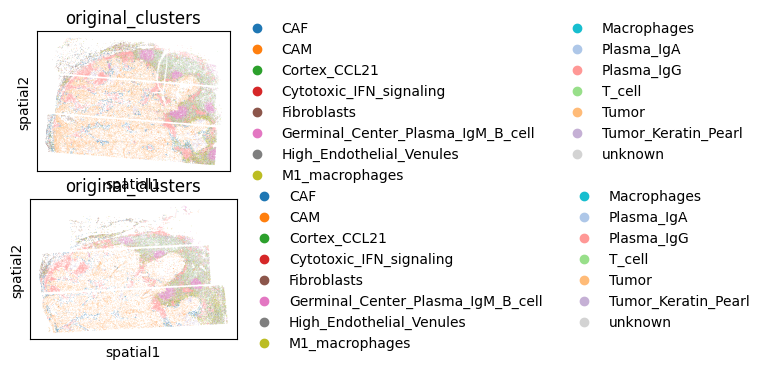

In [4]:
color_dict = {
    'CAF': '#1f77b4',  # Blue
    'CAM': '#ff7f0e',  # Orange
    'Cortex_CCL21': '#2ca02c',  # Green
    'Cytotoxic_IFN_signaling': '#d62728',  # Red
    'Dendritic_cells': '#9467bd',  # Purple
    'Fibroblasts': '#8c564b',  # Brown
    'Germinal_Center_Plasma_IgM_B_cell': '#e377c2',  # Pink
    'High_Endothelial_Venules': '#7f7f7f',  # Gray
    'M1_macrophages': '#bcbd22',  # Olive
    'Macrophages': '#17becf',  # Cyan
    'Plasma_IgA': '#aec7e8',  # Light Blue
    'Plasma_IgG': '#ff9896',  # Light Red
    'T_cell': '#98df8a',  # Light Green
    'Tumor': '#ffbb78',  # Peach
    'Tumor_Keratin_Pearl': '#c5b0d5',  # Lavender
    'unknown': '#d3d3d3'  # Light Gray
}

fig, axes = plt.subplots(2, 1, figsize=(6, 4))
sc.pl.spatial(ad, color='original_clusters', spot_size=30, ax=axes[0], palette=color_dict, show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=30, ax=axes[1], palette=color_dict, show=False)
plt.show()

0 of 40692
10000 of 40692
20000 of 40692
30000 of 40692
40000 of 40692
40691 of 40692


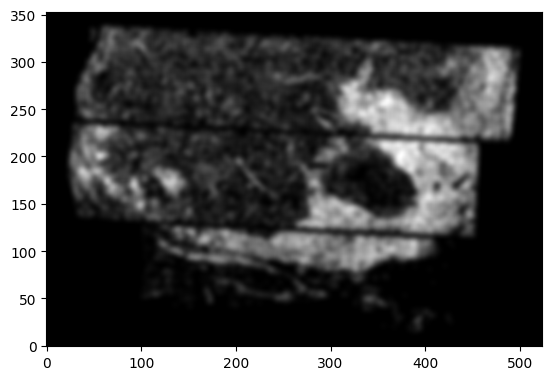

In [5]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 57057
10000 of 57057
20000 of 57057
30000 of 57057
40000 of 57057
50000 of 57057
57056 of 57057


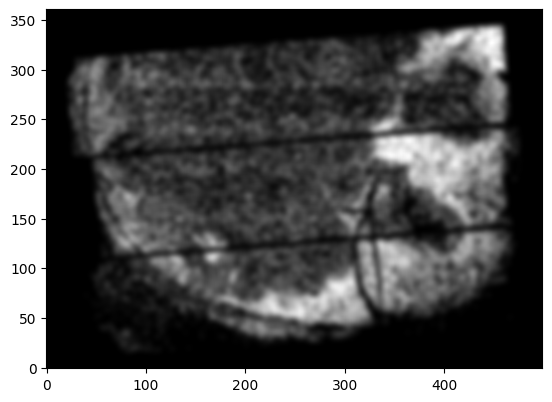

In [6]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

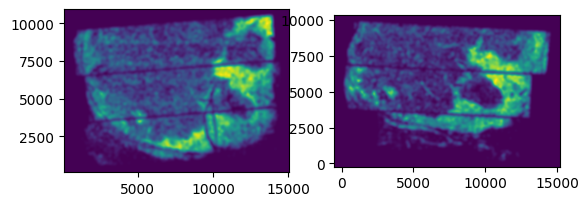

In [7]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

In [12]:
np.savez('./npz_data/25', x=XI,y=YI,I=I)
np.savez('./npz_data/26', x=XJ,y=YJ,I=J)

In [14]:
# read from file
pointsIlist = np.load('./npz_data/17_curves.npy', allow_pickle=True).tolist()
print(pointsIlist)
pointsJlist = np.load('./npz_data/19_curves.npy', allow_pickle=True).tolist()
print(pointsJlist)

{'0': [(11003.752953255675, 6358.713322972884)], '1': [(9995.365856481481, 8135.9955810374)]}
{'0': [(11667.35823067266, 7525.599605160409)], '1': [(10331.874359704918, 8927.857669676538)]}


In [ ]:
pointsIlist = {'0': [(11003.752953255675, 6358.713322972884)], '1': [(9995.365856481481, 8135.9955810374)]}
pointsJlist = {'0': [(11667.35823067266, 7525.599605160409)], '1': [(10331.874359704918, 8927.857669676538)]}

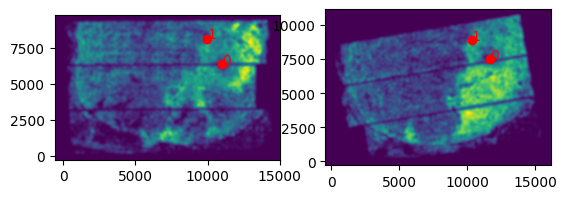

In [15]:
# convert to array
pointsI = []
pointsJ = []

# Jean's note: a bit odd to me that the points are stored as y,x
## instead of x,y but all downstream code uses this orientation
for i in pointsIlist.keys():
    pointsI.append([pointsIlist[i][0][1], pointsIlist[i][0][0]])
for i in pointsJlist.keys():
    pointsJ.append([pointsJlist[i][0][1], pointsJlist[i][0][0]])

pointsI = np.array(pointsI)
pointsJ = np.array(pointsJ)

# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow((I.transpose(1,2,0).squeeze()), extent=extentI) # just want 201x276 matrix
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ) # just want 201x276 matrix
# with points
ax[0].scatter(pointsI[:,1], pointsI[:,0], c='red')
ax[1].scatter(pointsJ[:,1], pointsJ[:,0], c='red')
for i in range(pointsI.shape[0]):
    ax[0].text(pointsI[i,1],pointsI[i,0],f'{i}', c='red')
    ax[1].text(pointsJ[i,1],pointsJ[i,0],f'{i}', c='red')
ax[0].invert_yaxis()
ax[1].invert_yaxis()

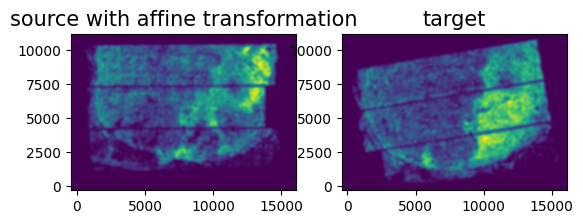

In [16]:
# set device for building tensors
if torch.cuda.is_available():
    torch.set_default_device('cuda:0')
else:
    torch.set_default_device('cpu')

# compute initial affine transformation from points
L,T = STalign.L_T_from_points(pointsI, pointsJ)
A = STalign.to_A(torch.tensor(L),torch.tensor(T))

# compute initial affine transformation from points
AI = STalign.transform_image_source_with_A(A, [YI,XI], I, [YJ,XJ])

#switch tensor from cuda to cpu for plotting with numpy
if AI.is_cuda:
    AI = AI.cpu()

fig,ax = plt.subplots(1,2)
ax[0].imshow((AI.permute(1,2,0).squeeze()), extent=extentJ)
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ)

ax[0].set_title('source with affine transformation', fontsize=15)
ax[1].set_title('target', fontsize=15)

ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 14min 50s, sys: 17 s, total: 15min 7s
Wall time: 17min 41s


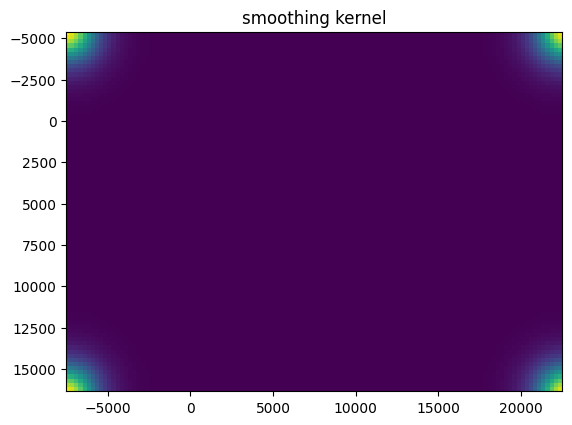

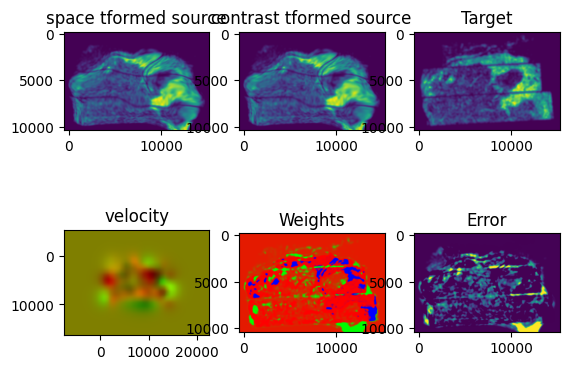

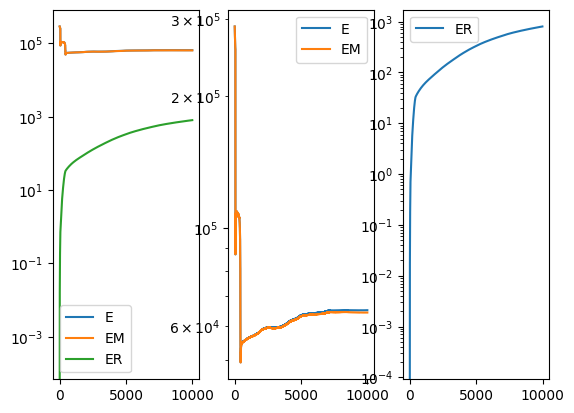

In [8]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
#             'pointsI':pointsI,
#             'pointsJ':pointsJ,
#             'L':L,'T':T,
            'niter':10000,
            'device':device,
            'epV': 20,
            'sigmaA': 0.1, #standard deviation of artifact intensities
            'sigmaB': 0.1, #standard deviation of background intensities
            'sigmaM': 0.1, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [9]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']

In [10]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

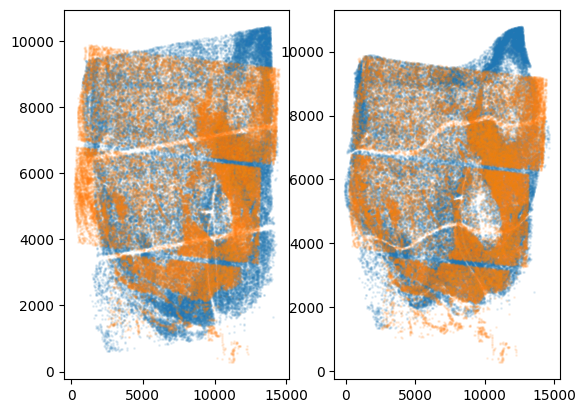

In [11]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.1, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.1, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.1, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.1, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

## LAA & ARI

In [12]:
from scipy.spatial import cKDTree
from sklearn.metrics import adjusted_rand_score


def find_nearest_points(f1, f2):
    """
    Find the nearest point in f2 for each point in f1 using batch processing.
    
    Args:
        f1 (numpy.ndarray): Array of shape (n_points_1, 2) representing points in f1.
        f2 (numpy.ndarray): Array of shape (n_points_2, 2) representing points in f2.
        batch_size (int): Number of points to process in each batch.
        
    """
    # Build a k-d tree for f2
    tree = cKDTree(f2)
    
    # Query the k-d tree for nearest neighbors of points in f1
    distances, nearest_indices = tree.query(f1)
        
    cnt = 0
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []

    for i in range(len(f1)):
        f1_cluster = ad_target.obs.iloc[i]['original_clusters']
        f2_cluster = ad.obs.iloc[nearest_indices[i]]['original_clusters']
        true_clusters_mapped_region.append(f1_cluster)
        mapped_clusters_mapped_region.append(f2_cluster)
        if f1_cluster == f2_cluster:
            cnt += 1 

    laa = cnt/len(f2)
    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
              
    return laa,ari


In [13]:
f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)

laa,ari = find_nearest_points(f1, f2)

print(laa)
print(ari)

0.23429202376570799
0.1370725941313012


## 3D

In [14]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,34_1204,Fibroblasts
1,34_1225,Fibroblasts
2,34_1232,CAF
3,34_1235,Fibroblasts
4,34_1256,Fibroblasts


In [15]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 17
results1['slice'] = '34'
results1

,index,original_clusters,X,Y,Z,slice
0,34_1204,Fibroblasts,579.332485,8664.058703,17,34
1,34_1225,Fibroblasts,585.962965,8632.561243,17,34
2,34_1232,CAF,591.370860,8612.205393,17,34
3,34_1235,Fibroblasts,582.863933,8720.862773,17,34
4,34_1256,Fibroblasts,588.340751,8404.901416,17,34
...,...,...,...,...,...,...
57052,34_137289,Germinal_Center_Plasma_IgM_B_cell,14648.584437,7163.792090,17,34
57053,34_137315,M1_macrophages,14577.499548,6714.150199,17,34
57054,34_137321,T_cell,14648.805433,7393.249797,17,34
57055,34_137346,unknown,14581.311463,7663.884507,17,34


In [16]:
results1.to_csv("34.csv", index=False)

In [17]:
dfs = ad_target.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,36_342,CAF
1,36_382,Fibroblasts
2,36_397,Fibroblasts
3,36_437,Fibroblasts
4,36_439,Fibroblasts


In [18]:
df3_1 = pd.DataFrame(
    {
        "X": x_target,
        "Y": y_target,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 18
results1['slice'] = '36'
results1

,index,original_clusters,X,Y,Z,slice
0,36_342,CAF,196.031388,5398.059343,18,36
1,36_382,Fibroblasts,206.956989,5175.735093,18,36
2,36_397,Fibroblasts,218.995098,5109.266340,18,36
3,36_437,Fibroblasts,221.770677,5460.952381,18,36
4,36_439,Fibroblasts,236.754717,5534.615502,18,36
...,...,...,...,...,...,...
40687,36_90890,M1_macrophages,14427.984584,8965.381295,18,36
40688,36_90900,Germinal_Center_Plasma_IgM_B_cell,14432.847025,9105.838527,18,36
40689,36_90933,M1_macrophages,14457.389171,8982.900169,18,36
40690,36_90945,M1_macrophages,14454.208453,9132.671920,18,36


In [19]:
results1.to_csv("36.csv", index=False)

## Plot 3D

In [ ]:
folder_path = '../lymph'

# List all CSV files in the folder
csv_files = [file for file in os.listdir(folder_path) if file.endswith('.csv')]
# csv_files
csv_files.sort(key=lambda x: int(''.join(filter(str.isdigit, x))))

# Read and combine all CSV files
combined_df = pd.concat([pd.read_csv(os.path.join(folder_path, file)) for file in csv_files])

# Display the combined DataFrame
combined_df


In [ ]:
unique_clusters = combined_df['original_clusters'].unique()

cmap = []
if len(unique_clusters) <= 10: # when no. of layers <=10
    for e in plt.get_cmap('tab10').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
else: # when 10< no. of layers <=40
    for e in plt.get_cmap('tab20').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))
    for e in plt.get_cmap('tab20b').colors:
        cmap.append(matplotlib.colors.rgb2hex(e))

# Create the dictionary with the combined clusters
c_dict = dict(zip(unique_clusters, cmap))
c_dict

In [ ]:
c_dict = {
    'CAF': '#1f77b4', 
    'CAM': '#aec7e8', 
    'Cortex_CCL21': '#ff7f0e', 
    'Cytotoxic_IFN_signaling': '#ffbb78', 
    'Dendritic_cells': '#2ca02c', 
    'Fibroblasts': '#98df8a', 
    'Germinal_Center_Plasma_IgM_B_cell': '#d62728', 
    'High_Endothelial_Venules': '#ff9896', 
    'M1_macrophages': '#9467bd', 
    'Macrophages': '#c5b0d5', 
    'Mast_cells': '#8c564b', 
    'Plasma_IgA': '#c49c94', 
    'Plasma_IgG': '#e377c2', 
    'T_cell': '#f7b6d2', 
    'Tumor': '#7f7f7f', 
    'Tumor_Keratin_Pearl': '#c7c7c7', 
    'unknown': '#bcbd22'
    }

In [ ]:
combined_df['celltype_colors'] = combined_df['original_clusters'].replace(c_dict)
combined_df.to_csv('STalign_lymph_aligned_coordinates_colors.csv', index=False)

In [2]:
def plot_3d(
    loc,
    val=None,
    color=None,
    figsize=(12,12),
    return_fig=True,
    elev=None,
    azim=None,
    roll=None,
    xlim=None,
    ylim=None,
    zlim=None,
    frameon=True,
    save_path=None,
    save_dpi=150,
    show=True,
    *args,
    **kwargs
):
    """Plot all slices stacked in 3D

    Plot all slices stacked with a given number of subplots rows and columns. Spots/cells colored by spatial domain.

    Args:
        loc: An array of the coordinates of each spots/cells in all slices, which the first three columns are X-axis, Y-axis, Z-axis coordinates.
        val: The colors of each spots/cells given in loc use to plot.
        color: The colors of each spots/cells given in loc use to plot.
        figsize: Size of the figure.
        return_fig: Whether to return the figure.
        elev: The elevation angle in the vertical plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        azim: The azimuth angle in the horizontal plane in degrees. If ``None`` then the initial value as specified in the ``Axes3D`` constructor is used.
        xlim: A tuple given the left and right xlims in X-axis.
        ylim: A tuple given the left and right xlims in Y-axis.
        zlim: A tuple given the left and right xlims in Z-axis.
        frameon: Whether to hide the coordinate axes.
        save_path: A string representing the path directory where the figure saved.
        save_dpi: The resolution in dots per inch.
        show: Whether to show the figure.

    Returns:
        A ``matplotlib.figure.Figure`` object
    """
    if 'marker' not in kwargs.keys():
        kwargs['marker'] = 'o'
    if 's' not in kwargs.keys():
        kwargs['s'] = 5
    if 'cmap' not in kwargs.keys():
        kwargs['cmap'] = 'Spectral_r'
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(projection='3d')
    if (elev is not None) and (azim is not None) and (roll is not None):
        ax.view_init(elev, azim, roll)
    if color is None:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=val,*args,**kwargs)
    else:
        ax.scatter(loc[:,0], loc[:,1], loc[:,2],c=color,*args,**kwargs)
    
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    if zlim is not None:
        ax.set_zlim(zlim)
    # ax.set_box_aspect([1, 1, 2])
    # ax.set_aspect('equal')
    if not frameon:
        plt.axis('off')
        plt.grid(b=None)
    if save_path is not None:
        print(save_path)
        plt.savefig(save_path,dpi=save_dpi,bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.close()
    if return_fig:
        return fig

In [4]:
combined_df = pd.read_csv('STalign_lymph_aligned_coordinates_colors.csv')
coords = combined_df[['X', 'Y', 'Z']]

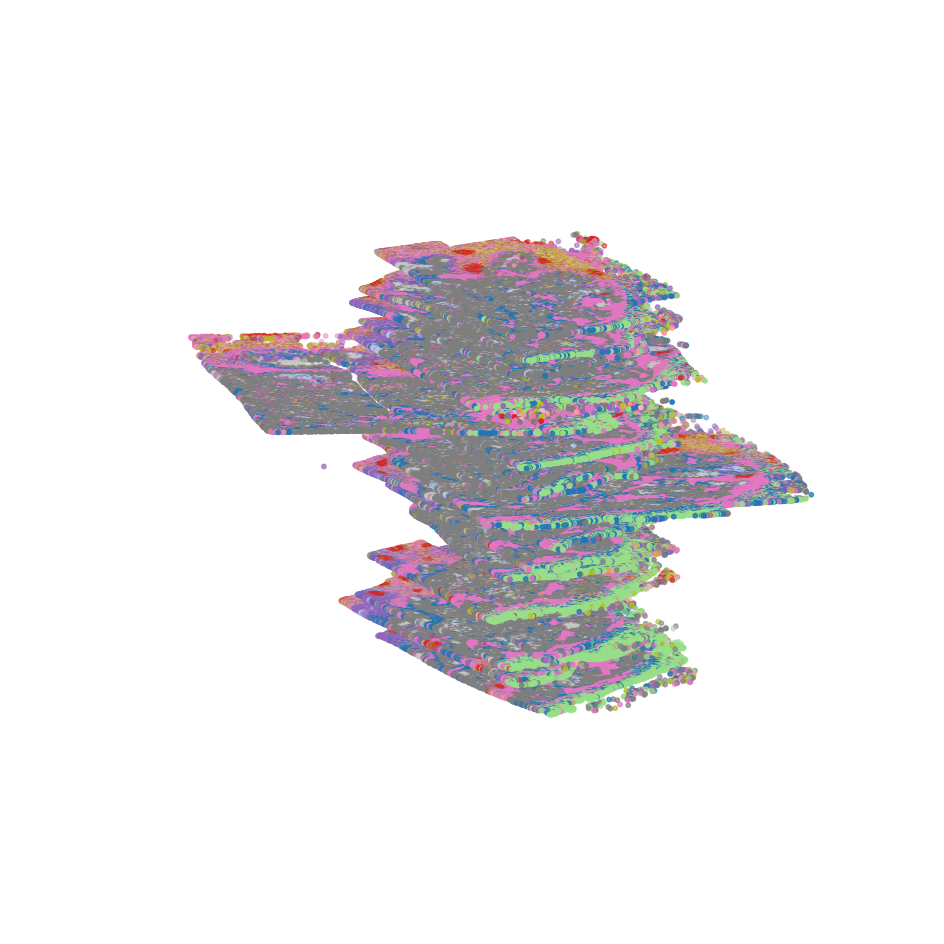

In [6]:
fig = plot_3d(coords.values, val=None, color=combined_df['celltype_colors'], elev=20, azim=150, roll=0, frameon=False, show=True, s=10, return_fig=True) # Scube is from SPACEL

fig.savefig('STalign_gtAndScube_merfish_3dviz_angle20_150_s=10.png', bbox_inches="tight")